# GAF-CNN — Training Output (gaf_cnn.sh)

**Everything the training phase of `gaf_cnn.sh` produced**

<small>Notebook 1 of 3 &middot; generated automatically from the output files of the `gaf_cnn.sh` run, so it is reproducible: every number below is read from the files the run produced.</small>

## 0. Setup — imports and paths

The cell below finds the `GAF_CNN_Complete` folder automatically, so the notebook works wherever the folder is placed.

In [1]:
import json, os, re, sys, glob, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink, Image as IPImage

%matplotlib inline


def find_bundle_root(start=None):
    """Walk up until we find the folder that contains run_output/gaf_cnn_sh."""
    p = Path(start or os.getcwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "run_output" / "gaf_cnn_sh" / "training_console.txt").exists():
            return cand
        if (cand / "training_console.txt").exists():      # notebook inside run_output
            return cand.parent.parent
    raise FileNotFoundError("Could not find run_output/gaf_cnn_sh - run the notebook from inside "
                            "the GAF_CNN_Complete folder")


BUNDLE = find_bundle_root()
RUN    = BUNDLE / "run_output" / "gaf_cnn_sh"
CODE   = BUNDLE / "code"
NB_DIR = BUNDLE / "notebooks"
DATA   = BUNDLE / "data"
sys.path.insert(0, str(CODE))

# keep line length sane in the tables
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

print("bundle folder :", BUNDLE)
print("run folder    :", RUN)
print("files in run  :", sorted(p.name for p in RUN.iterdir()))

bundle folder : /home/user/CHEM_GAF_CNN/GAF_CNN_Complete
run folder    : /home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh
files in run  : ['model', 'training_console.txt', 'training_console_clean.txt', 'training_curve_1_1.png', 'training_curve_1_2.png', 'training_history.json']


## 1. What was run

The original command line script of the repository:

```bash
cd python
bash gaf_cnn.sh
# -> python3 ./gaf_cnn.py --base_dir "../data/gafimages/shuffled/" --plot \
#        --nb_epoch 4000 --batch_size 16 --patience 1000
```

The training phase trains the small CNN (`simple_cnn`) on the `shuffled/Train` split and validates on
`shuffled/Val`. The next cells show the configuration it printed and the results it produced.

In [2]:
# the console output of the run (colours and progress-bar spam removed)
log = (RUN / "training_console.txt").read_text(errors="replace")
log = re.sub(r"\x1b\[[0-9;]*[A-Za-z]", "", log)

def clean(text):
    out = []
    for line in text.splitlines():
        if "\r" in line:
            line = line.split("\r")[-1]
        out.append(line.replace("\b", "").rstrip())
    return "\n".join(out)

log = clean(log)
print("console log:", len(log.splitlines()), "lines,", len(log), "characters")

cfg = {}
for key in ["base_dir", "nb_epochs", "batch_size", "patience"]:
    m = re.search(rf"^{key}:\s*(.+)$", log, re.MULTILINE)
    if m:
        cfg[key] = m.group(1).strip()
found = re.findall(r"Found (\d+) images belonging to (\d+) classes", log)
if found:
    cfg["train_images"], cfg["classes"] = int(found[0][0]), int(found[0][1])
if len(found) > 1:
    cfg["validation_images"] = int(found[1][0])
m = re.search(r"LEARNING - (\S+)", log)
if m:
    cfg["model_file"] = m.group(1)
m = re.search(r"Prediction of (\d+) rows", log)
if m:
    cfg["test_images"] = int(m.group(1))

display(pd.DataFrame(cfg.items(), columns=["setting", "value"]).set_index("setting"))

console log: 19872 lines, 1003186 characters


,value
setting,
base_dir,../data/gafimages/shuffled/
nb_epochs,4000
batch_size,16
patience,1000
train_images,69
classes,5
validation_images,20
model_file,CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras
test_images,25


## 2. How the training went

The run's own history (captured while `model.fit()` ran) gives the exact accuracy / loss of every epoch.

In [3]:
history = json.loads((RUN / "training_history.json").read_text())
epochs_run = len(history["accuracy"])

epochs = pd.DataFrame({
    "epoch": range(1, epochs_run + 1),
    "train_accuracy": history["accuracy"],
    "train_loss": history["loss"],
    "val_accuracy": history["val_accuracy"],
    "val_loss": history["val_loss"],
})
epochs.to_csv(RUN / "training_epochs.csv", index=False)   # full table for download

best_i = int(epochs["val_loss"].idxmin())
best = epochs.loc[best_i]

summary = pd.DataFrame({
    "value": [
        cfg.get("nb_epochs"), epochs_run,
        int(epochs["epoch"].max()) if int(epochs["epoch"].max()) < int(cfg.get("nb_epochs", 0)) else "not needed - all epochs completed",
        best["epoch"], f"{best['val_loss']:.6f}", f"{best['val_accuracy'] * 100:.2f} %",
        f"{epochs.iloc[-1]['train_accuracy'] * 100:.2f} %", f"{epochs.iloc[-1]['train_loss']:.6f}",
        f"{epochs['val_accuracy'].max() * 100:.2f} %",
    ]},
    index=["epochs requested", "epochs actually run", "early stopping",
           "best epoch (lowest val_loss)", "best val_loss", "val_accuracy at best epoch",
           "final train accuracy", "final train loss", "best val_accuracy seen"],
)
display(Markdown("### Training summary"))
display(summary)

### Training summary

,value
epochs requested,4000
epochs actually run,2418
early stopping,2418
best epoch (lowest val_loss),1418.0
best val_loss,0.024688
val_accuracy at best epoch,100.00 %
final train accuracy,89.86 %
final train loss,0.179620
best val_accuracy seen,100.00 %


### Training curves produced by the script (`--plot`)

`training_curve_1_1.png`

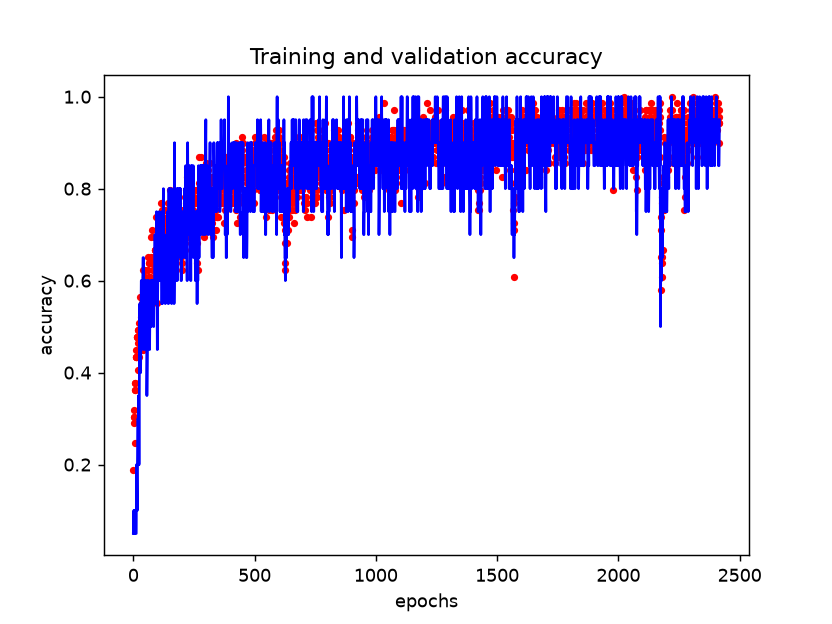

`training_curve_1_2.png`

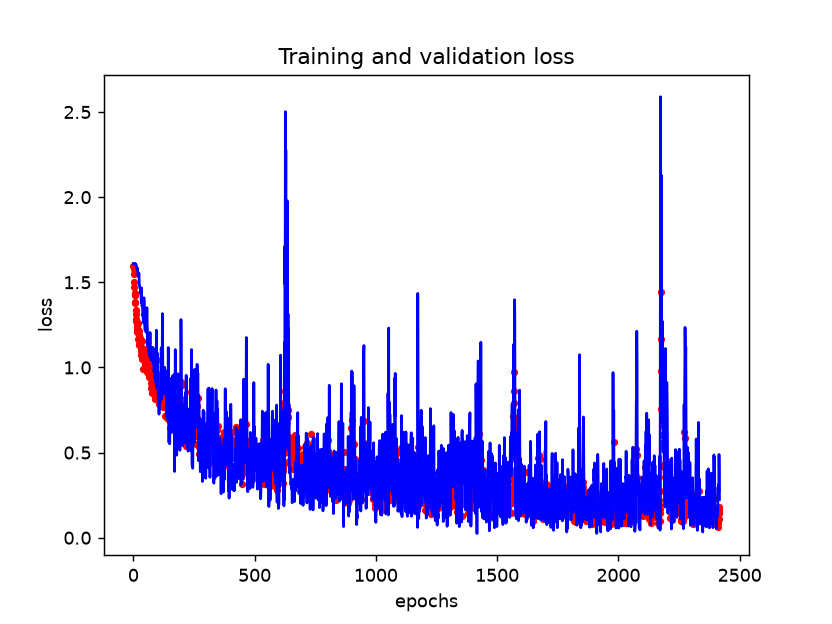

In [4]:
# the two figures the script itself plotted (captured from plt.show())
display(Markdown("### Training curves produced by the script (`--plot`)"))
for png in sorted(RUN.glob("training_curve_*.png")):
    display(Markdown(f"`{png.name}`"))
    display(IPImage(filename=str(png), width=560))

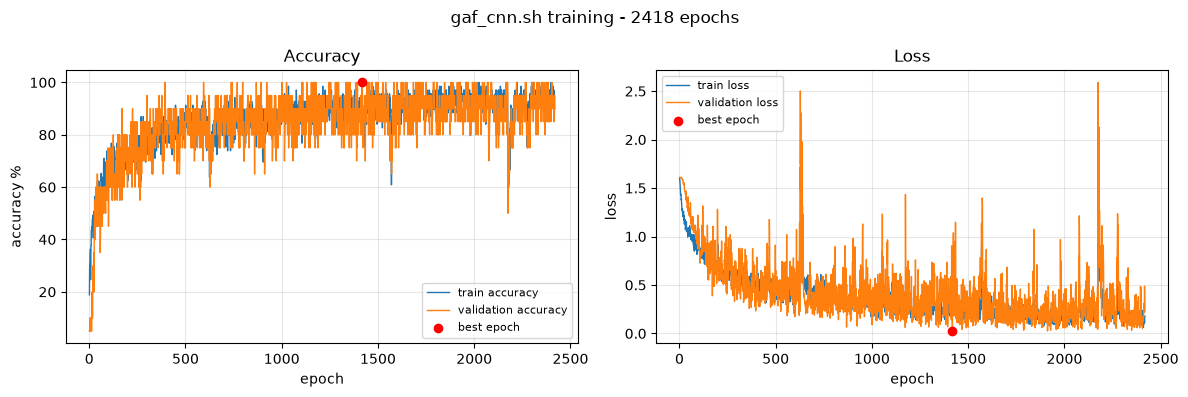

### Epoch table (2418 epochs)

First 5 epochs:

,epoch,train_accuracy,train_loss,val_accuracy,val_loss
0,1,0.188406,1.596870,0.05,1.610087
1,2,0.289855,1.575964,0.05,1.610072
2,3,0.304348,1.548562,0.10,1.609272
3,4,0.304348,1.503829,0.05,1.609809
4,5,0.318841,1.471000,0.05,1.608011


Best epoch (lowest validation loss):

,epoch,train_accuracy,train_loss,val_accuracy,val_loss
1415,1416,0.855072,0.523159,0.90,0.434457
1416,1417,0.840580,0.464971,0.90,0.239829
1417,1418,0.855072,0.371400,1.00,0.024688
1418,1419,0.898551,0.295590,0.90,0.373529
1419,1420,0.913043,0.241374,0.85,0.839452


Last 5 epochs:

,epoch,train_accuracy,train_loss,val_accuracy,val_loss
2413,2414,0.971014,0.143023,0.85,0.311199
2414,2415,0.942029,0.147767,0.85,0.273317
2415,2416,0.956522,0.108646,0.85,0.488933
2416,2417,0.942029,0.163730,0.90,0.390771
2417,2418,0.898551,0.179620,0.95,0.224622


Complete table also saved as `run_output/gaf_cnn_sh/training_epochs.csv` (2418 rows).

In [5]:
# clean redraw from the exact history, plus the table of epochs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs["epoch"], epochs["train_accuracy"] * 100, label="train accuracy", lw=1)
axes[0].plot(epochs["epoch"], epochs["val_accuracy"] * 100, label="validation accuracy", lw=1)
axes[0].scatter([best["epoch"]], [best["val_accuracy"] * 100], color="red", zorder=5, label="best epoch")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("accuracy %"); axes[0].set_title("Accuracy")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

axes[1].plot(epochs["epoch"], epochs["train_loss"], label="train loss", lw=1)
axes[1].plot(epochs["epoch"], epochs["val_loss"], label="validation loss", lw=1)
axes[1].scatter([best["epoch"]], [best["val_loss"]], color="red", zorder=5, label="best epoch")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("loss"); axes[1].set_title("Loss")
axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
fig.suptitle(f"gaf_cnn.sh training - {epochs_run} epochs", fontsize=12)
fig.tight_layout()
plt.show()

display(Markdown(f"### Epoch table ({epochs_run} epochs)"))
display(Markdown("First 5 epochs:")); display(epochs.head())
display(Markdown("Best epoch (lowest validation loss):")); display(epochs.iloc[max(0, best_i - 2): best_i + 3])
display(Markdown("Last 5 epochs:")); display(epochs.tail())
display(Markdown(f"Complete table also saved as `run_output/gaf_cnn_sh/training_epochs.csv` "
                 f"({epochs_run} rows)."))

## 3. The model this training produced

`ModelCheckpoint` saved the best model (lowest `val_loss`) to disk.

In [6]:
import tensorflow as tf
import zipfile
from gaf_cnn import simple_cnn
%matplotlib inline

CLASSES = ["Benzochinone", "Catecolo", "Ferro-Ferri", "Idrochinone", "Idrochinone-Benzochinone"]

model_files = sorted(RUN.glob("model/*.keras")) or sorted(CODE.glob("CNN_*classes_*.keras"))
model_path = model_files[0]
print("model file :", model_path.name)
print("size       :", f"{model_path.stat().st_size:,} bytes")
print("sha256     :", hashlib.sha256(model_path.read_bytes()).hexdigest()[:32], "...")

with zipfile.ZipFile(model_path) as z:
    meta = json.loads(z.read("metadata.json").decode())
print("saved by   :", "keras", meta.get("keras_version"), "on", meta.get("date_saved"))

# rebuild the architecture with the repository's own function, then load the trained weights
trained = simple_cnn(n_classes=len(CLASSES))
trained(tf.zeros((1, 224, 224, 3)))
trained.load_weights(model_path)
print("\nmodel architecture (rebuild of the repository's simple_cnn()):")
trained.summary()

model file : CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras
size       : 230,098 bytes
sha256     : 233c5a8382b8cef742f35b55b4175703 ...
saved by   : keras 3.3.3 on 2026-10-13@14:55:55


/home/user/.venv/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



model architecture (rebuild of the repository's simple_cnn()):


/home/user/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:415: UserWarning: Skipping variable loading for optimizer 'SGD', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 16)   │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 8)        │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 1, 1, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5)              │            20 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,641 (80.63 KB)

 Trainable params: 20,631 (80.59 KB)

 Non-trainable params: 10 (40.00 B)

## 4. Files produced by the training phase

In [7]:
files = [
    ("Full console output of gaf_cnn.sh", RUN / "training_console.txt"),
    ("Training history (accuracy/loss per epoch)", RUN / "training_history.json"),
    ("Epoch table (CSV)", RUN / "training_epochs.csv"),
    ("Trained model (best val_loss)", model_path),
]
files += [("Training curve (as plotted by the script)", p) for p in sorted(RUN.glob("training_curve_*.png"))]

display(Markdown("### Download"))
for label, p in files:
    if Path(p).exists():
        display(FileLink(str(p), result_html_prefix=f"{label}: "))
    else:
        print(f"{label}: not found ({p})")

### Download

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/training_console.txt

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/training_history.json

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/training_epochs.csv

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/model/CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/training_curve_1_1.png

/home/user/CHEM_GAF_CNN/GAF_CNN_Complete/run_output/gaf_cnn_sh/training_curve_1_2.png